In [1]:
# Add the root path of the pyqula library
import os ; import sys
try: sys.path.append(os.environ["PYQULAROOT"]) # add the library via environmental variable
except: pass
try: from pyqula import geometry # check if the library is present
except: # pyqula not installed
    print("pyqula needs to be installed, installing it")
    import subprocess ; subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade","pyqula"])

# some default parameters in matplotlib
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [20, 8]
plt.rcParams['font.size'] = 22
plt.rcParams['image.cmap'] = 'coolwarm'


import numpy as np

# Advanced Quantum Materials, session 9: Excitations and impurities in quantum materials
In this session we will address how impurities, disorder and vacancies alter the electronic structure of metals, insulators, superconductors and quasicrystals

### Contents
- Impact of disorder and single impurities in metals, insulators and superconductors
- Localization and delocalization in quasicrystals and disordered systems
- Non-magnetic impurities and vacancies in topological superconductors and insulators
- The charge-charge response function

### Learning outcomes
- To understand the relation between electronic structure and response function
- To understand the impact of impurities in a metal
- To understand the impact of impurities in a superconductor
- Rationalize localization and delocalization in quasiperiodic models

### About the exercises
The notebooks contain two types of exercises, with each exercise containing **Quiz** questions to answer
- ***Core***: basic exercises you should understand in each session
- ***Challenge***: advanced exercises to dive deeper into concepts, not necessary to understand in full in each session

### It is not necessary to complete all the exercises, you can just focus on those that sound most interesting for you.

## The impact of disorder in different systems (***Core***)
Here we will show how disorder affects different electronic states in a different way

Comparing how each gap responds to increasing disorder strength $W$ reveals its nature: the s-wave superconducting gap is protected by Anderson's theorem and survives disorder essentially unchanged, the topological p-wave gap is pair-breaking-sensitive and closes well before the s-wave gap does, and the band insulator's gap is a single-particle effect that simply gets filled in by localized in-gap states as $W$ grows, with no symmetry protecting it either way.

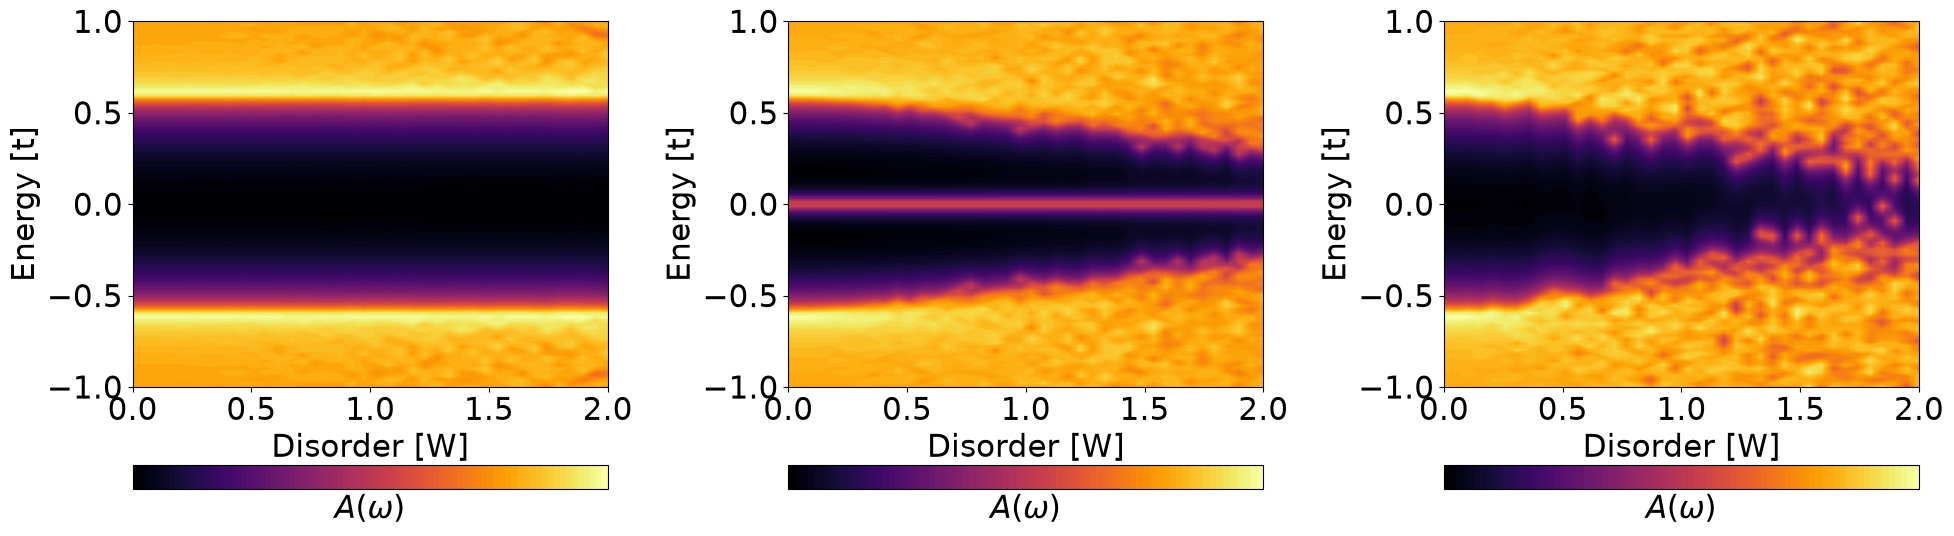

In [2]:
def disorder_sweep(H,N=100):
    """Sweep over disorder strength, and plot the DOS"""
    ws = np.linspace(0.,2.,40) # disorder configurations
    energies = np.linspace(-1.,1.,100) # energies for the DOS
    Hs = H.copy() ; Hs = Hs.get_supercell(N) # make a supercell
    Hs.dimensionality = 0 ; Hs.geometry.dimensionality = 0 # make a finite system
    dmap = [] # storage for the DOS
    for w in ws:
        Hi = Hs.copy() # make a copy
        fdis = lambda r: w*(np.random.random()-0.5) # disorder potential
        Hi.add_onsite(fdis) # add the disorder
        (es,ds) = Hi.get_dos(energies=energies,delta=2e-2,nk=1) # compute DOS
        dmap.append(ds) # store DOS
    dmap = np.array(dmap).reshape((len(ws),len(energies))).T
    plt.contourf(ws,energies,np.log(dmap),levels=80,cmap="inferno")
    plt.xlabel("Disorder [W]") ; plt.ylabel("Energy [t]")
    plt.colorbar(ticks=[],label="$A(\\omega)$",orientation="horizontal")

from pyqula import geometry
h0 = geometry.bichain().get_hamiltonian()
fig = plt.figure(figsize=(20,6)) # create the figure

# s-wave SC
hs = h0.copy() ; hs.add_pairing(mode="swave",delta=0.6)
plt.subplot(1,3,1) ;disorder_sweep(hs)

# topological p-wave SC
hp = h0.copy() ; hp.add_onsite(2.0) ; hp.add_exchange([0.,2.,.0]) ; hp.add_pairing(mode="pwave",delta=0.3)
plt.subplot(1,3,2) ;disorder_sweep(hp)

# conventional insulator
hi = h0.copy() ; hi.add_sublattice_imbalance(0.6)
plt.subplot(1,3,3) ; disorder_sweep(hi)

plt.tight_layout()

### Quiz
- How can you infer from the spectra the nature of each ground state?
- Make the system periodic, how does the spectra change and why?

## The impact of a strong impurity (***Core***)
Here we will show how disorder affects different electronic states in a different way

Here the same three gaps are probed with a single strong impurity (via the embedding method) rather than random disorder throughout the lattice. The qualitative conclusion is the same: the s-wave gap stays essentially unaffected by a single non-magnetic impurity, while the insulator and the topological p-wave superconductor develop clear in-gap bound states as the impurity strength grows.

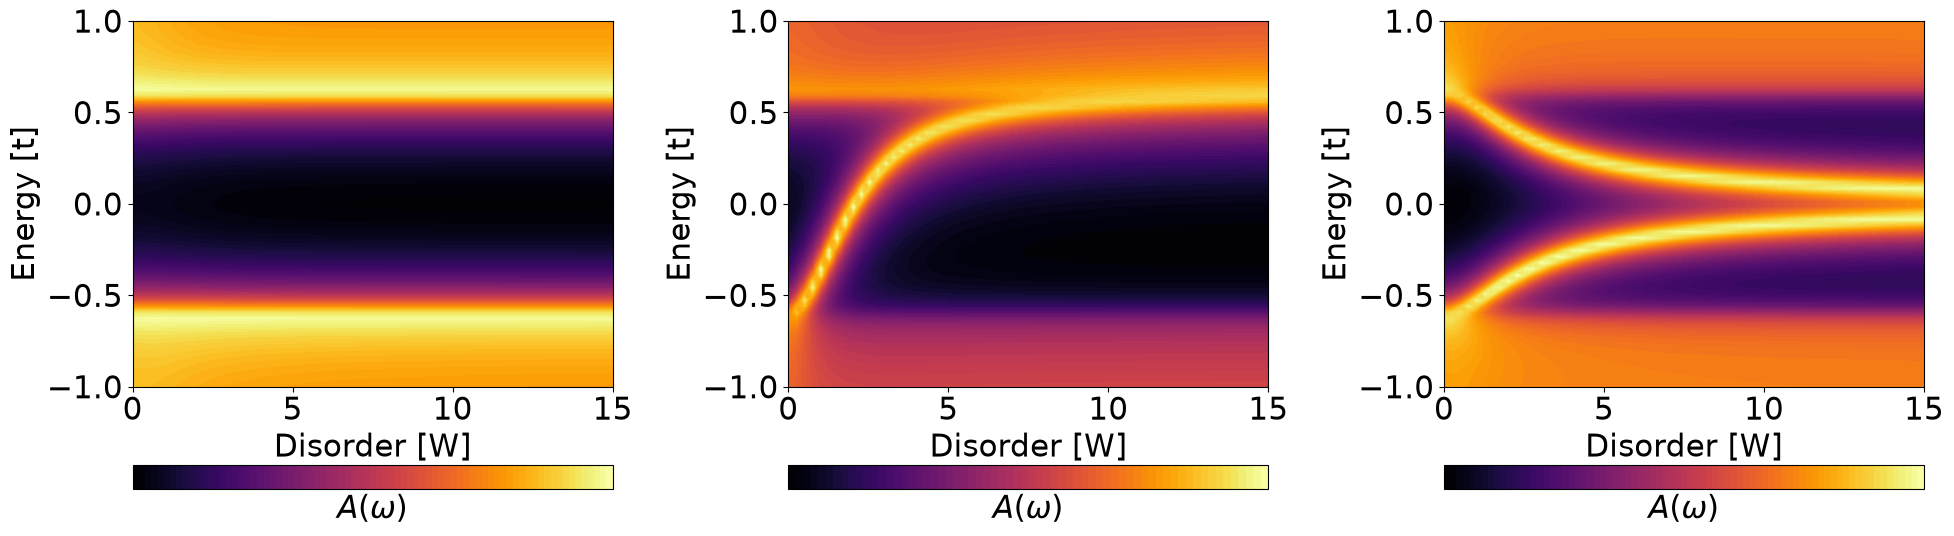

In [3]:
from pyqula import potentials,embedding

def disorder_sweep(H):
    """Sweep over the impurity strength, and plot the DOS"""
    ws = np.linspace(0.,15.,60) # disorder configurations
    energies = np.linspace(-1.,1.,60) # energies for the DOS
    H = H.get_supercell(2) # make a bigger unit cell
    dmap = [] # storage for the DOS
    for w in ws:
        Hi = H.copy() # make a copy
        fdis = potentials.impurity(H.geometry.r[0],v=w) # disorder potential
        Hi.add_onsite(fdis) # add the disorder
        eb = embedding.Embedding(H,m=Hi) # create an embedding object 
        (es,ds) = eb.multidos(es=energies,delta=4e-2,operator="electron") # compute LDOS
        dmap.append(ds) # store DOS
    dmap = np.array(dmap).reshape((len(ws),len(energies))).T
    plt.contourf(ws,energies,np.log(dmap),levels=80,cmap="inferno")
    plt.xlabel("Disorder [W]") ; plt.ylabel("Energy [t]")
    plt.colorbar(ticks=[],label="$A(\\omega)$",orientation="horizontal")

from pyqula import geometry
h0 = geometry.bichain().get_hamiltonian()
fig = plt.figure(figsize=(20,6)) # create the figure

# s-wave SC
hs = h0.copy() ; hs.add_pairing(mode="swave",delta=0.6)
plt.subplot(1,3,1) ; disorder_sweep(hs)

# conventional insulator
hi = h0.copy() ; hi.add_sublattice_imbalance(-0.6)
plt.subplot(1,3,2) ; disorder_sweep(hi)


# topological p-wave SC
hp = h0.copy() ; hp.add_onsite(2.0) ; hp.add_exchange([0.,2.,.0]) ; hp.add_pairing(mode="pwave",delta=0.3) # spinless p-wave
plt.subplot(1,3,3) ;disorder_sweep(hp)

plt.tight_layout()

### Quiz
- How can you infer which is the nature of each ground state?
- Decrease the value of the gaps. What happens and why?

## Impurity in a 1d metal (***Core***)
Let us first look at the modulation of the local density of states in a one-dimensional metal

A single impurity in a metal scatters electrons at the Fermi level, producing Friedel oscillations in the local density of states, $\delta\rho(x)\propto \cos(2k_F x)/x$, with a wavelength $\pi/k_F$ set entirely by the Fermi momentum. Changing the chemical potential changes $k_F$ (readable directly off the band structure on the right) and therefore the oscillation wavelength.

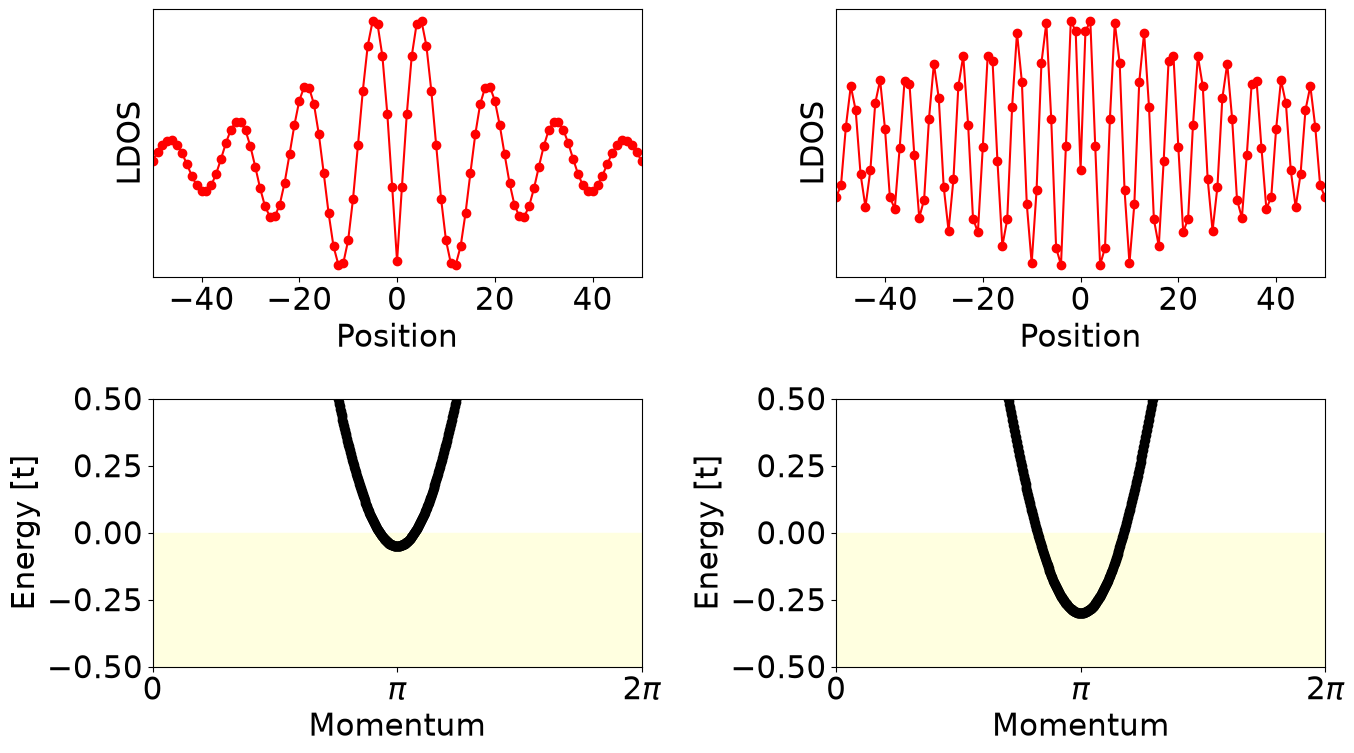

In [4]:
from pyqula import geometry
from pyqula import embedding

fig = plt.figure(figsize=(14,8))


mus = [1.95,1.7] # loop over chemical potentials
imu = 0 # counter for the chemical potential
for mu in mus:
    W = 0.2 # strength of the impurity
    g = geometry.chain() # create geometry of a chain
    h = g.get_hamiltonian(has_spin=False,tij=[1]) # get the Hamiltonian,spinless
    h.add_onsite(mu) # shift the chemical potential
    # first compute the bands of the pristine system
    (k,e) = h.get_bands(nk=1000)
    # now compute the LDOS in the presence of an impurity
    # this uses a special method to compute individual impurities in infinite pristine systems
    hv = h.copy() # copy Hamiltonian to create a defective one
    hv.add_onsite(lambda r: (np.sum((r - g.r[0])**2)<1e-2)*W) # add a defect
    eb = embedding.Embedding(h,m=hv) # create an embedding object
    (x,y,d) = eb.get_ldos(nsuper=101,energy=0.,delta=1e-2,nk=400) # compute LDOS
    # and plot everything
    plt.subplot(2,2,imu+1)
    # plot the LDOS with an impurity
    plt.plot(x,d,marker="o",c="red")
    plt.xlim([min(x),max(x)])
    plt.yticks([]) ; plt.xlabel("Position") ; plt.ylabel("LDOS")
 
    plt.subplot(2,2,imu+3)
    # plot the pristine band structure
    k = k/max(k) # normalize
    plt.xlim([min(k),max(k)]) ; plt.ylim(-0.5,0.5)
    plt.fill_between([0,1],-10,0,color="lightyellow")
    plt.scatter(k,e,c="black")
    plt.xticks([0,0.5,1],labels=["0","$\\pi$","2$\\pi$"]) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]")
    imu += 1
    
plt.tight_layout()

### Quiz
- Why is the local density of states oscillating around the impurity?
- Why does the wavelength of the oscillation depend on the chemical potential?
- Change the chemical potential, how do the oscillations change? Can you predict the wavelength from the band structure?

## Impurities in a 2d metal (***Core***)
We will now see how a 2d metal behaves in the presence of an impurity

The same Friedel-oscillation physics appears in 2D: ripples in the LDOS with wavelength $\pi/k_F$ radiating out from the impurity, decaying algebraically with distance rather than exponentially, since they come from scattering off the sharp Fermi surface — the same mechanism, now visible as circular fringes instead of a 1D standing wave.

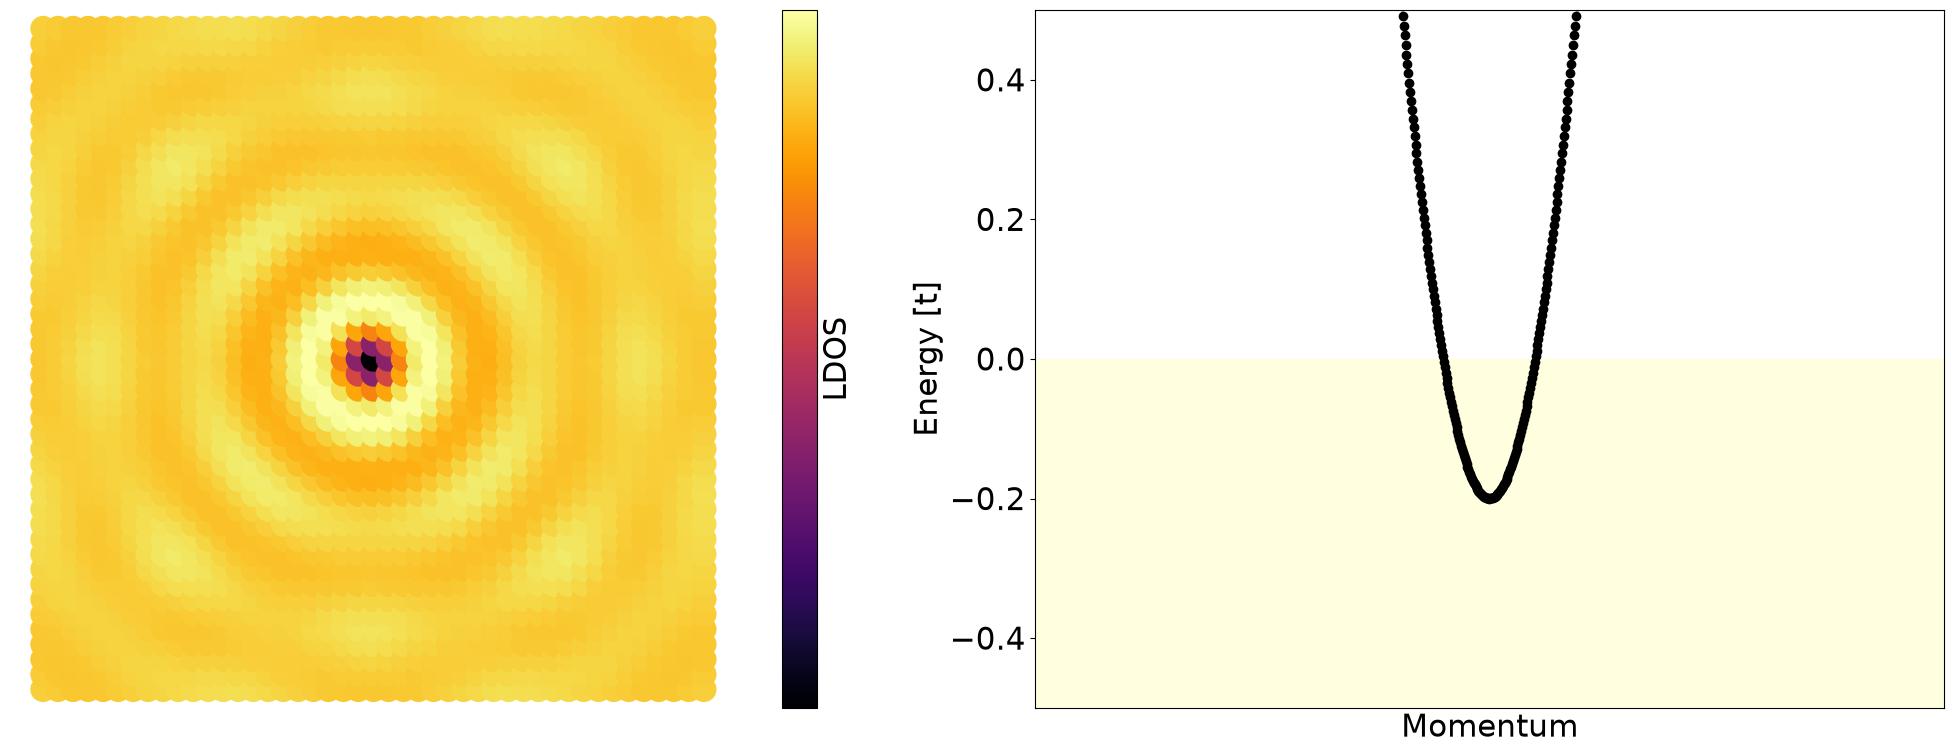

In [5]:
from pyqula import geometry
from pyqula import embedding


fig = plt.figure(figsize=(20,8))

mu = 3.8 # chemical potential
W = 10 # strength of the impurity
g = geometry.square_lattice() # create geometry of a square lattice
h = g.get_hamiltonian(has_spin=False) # get the Hamiltonian,spinless
h.add_onsite(mu) # shift the chemical potential

# firs compute the band structure of the pristine system
(k,e) = h.get_bands(nk=1000)

# now compute the LDOS in the presence of an impurity
# this uses a special method to compute individual impurities in infinite pristine systems

hv = h.copy() # copy Hamiltonian to create a defective one
hv.add_onsite(lambda r: (np.sum((r - g.r[0])**2)<1e-2)*W) # add a defect
eb = embedding.Embedding(h,m=hv) # create an embedding object
NS = 45 # number of supercells
(x,y,d) = eb.get_ldos(nsuper=NS,energy=0.,delta=1e-2,nk=100) # compute LDOS
 
# now plot the LDOS with an impurity
plt.subplot(1,2,1)
plt.scatter(x,y,c=d,marker="o",cmap="inferno",s=300)
xy = NS/3. # maximum range
plt.xlim([-xy,xy]) ; plt.ylim([-xy,xy])
plt.yticks([]) ; plt.xticks([]); plt.xlabel("y") ; plt.ylabel("x") ; plt.axis("equal") ; plt.axis("off")
plt.colorbar(ticks=[],label="LDOS")

# now plot the pristine band structure
plt.subplot(1,2,2)
k = k/max(k) # normalize
plt.xlim([min(k),max(k)]) ; plt.ylim(-0.5,0.5)
plt.fill_between([0,1],-10,0,color="lightyellow")
plt.scatter(k,e,c="black")
plt.xticks([]) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]")
    
plt.tight_layout()

### Quiz
- What is the origin of the oscillations in the LDOS?
- If you change the chemical potential, how do the oscillations change?
- Can you predict the wavelength of the oscillations from the band structure?

## Impurity in an electronic insulator (***Core***)
We will now see how an impurity affects a 1D insulator

In a gapped system there is no Fermi surface to produce algebraic Friedel oscillations; the impurity response instead decays exponentially, with a localization length $\xi\sim v_F/E_g$ set by the gap. A larger gap means a shorter $\xi$, so the LDOS converges to its uniform bulk value over fewer sites — exactly the faster convergence seen for the bigger of the two gaps.

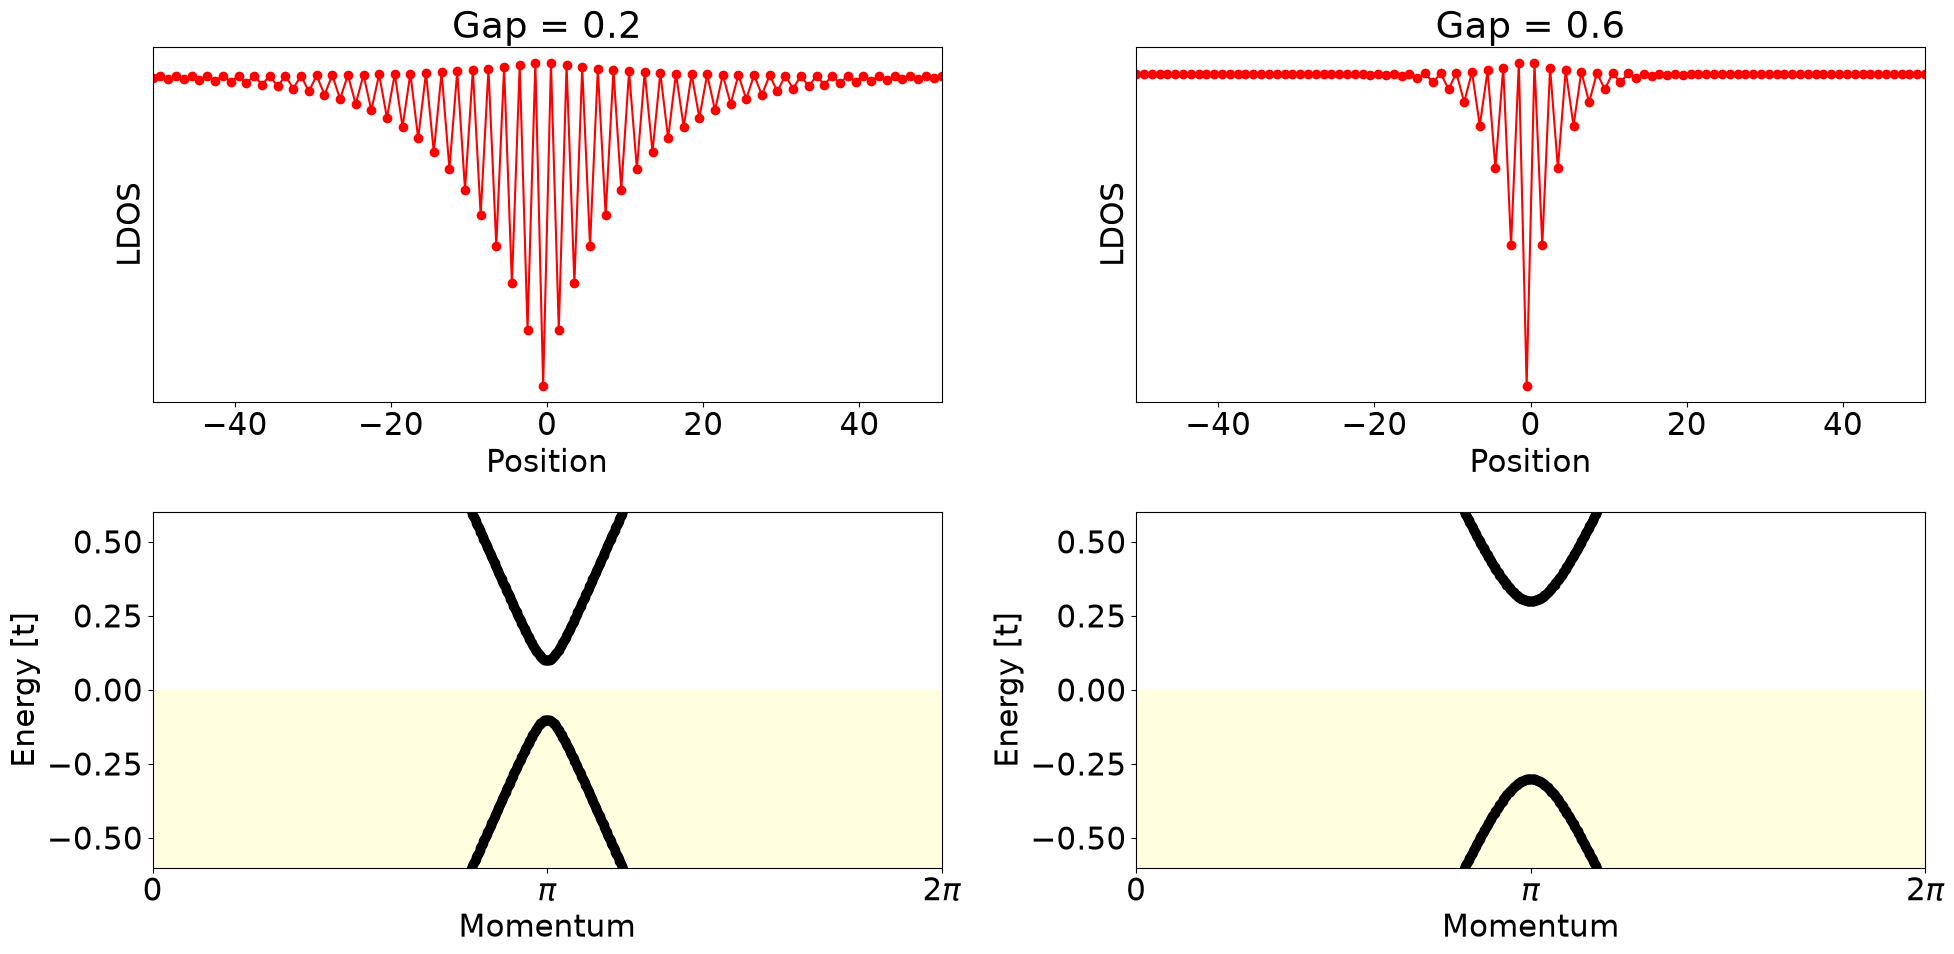

In [6]:
from pyqula import geometry
from pyqula import embedding

fig = plt.figure(figsize=(20,10))


gaps = [0.1,0.3] # loop over gaps
imu = 0 # counter for the chemical potential
for gap in gaps:
    W = 0.2 # strength of the impurity
    g = geometry.bichain() # create geometry of a chain
    h = g.get_hamiltonian(has_spin=False,tij=[1]) # get the Hamiltonian,spinless
#    h.add_onsite(mu) # shift the chemical potential
    h.add_sublattice_imbalance(gap)
    # first compute the bands of the pristine system
    (k,e) = h.get_bands(nk=1000)
    # now compute the LDOS in the presence of an impurity
    # this uses a special method to compute individual impurities in infinite pristine systems
    hv = h.copy() # copy Hamiltonian to create a defective one
    hv.add_onsite(lambda r: (np.sum((r - g.r[0])**2)<1e-2)*W) # add a defect
    eb = embedding.Embedding(h,m=hv) # create an embedding object
    (x,y,d) = eb.get_ldos(nsuper=51,energy=0.,delta=1e-2,nk=400) # compute LDOS
    # and plot everything
    plt.subplot(2,2,imu+1) ; plt.title("Gap = "+str(2*gap))
    # plot the LDOS with an impurity
    plt.plot(x,d,marker="o",c="red")
    plt.xlim([min(x),max(x)])
    plt.yticks([]) ; plt.xlabel("Position") ; plt.ylabel("LDOS")
 
    plt.subplot(2,2,imu+3)
    # plot the pristine band structure
    k = k/max(k) # normalize
    plt.xlim([min(k),max(k)]) ; plt.ylim(-2*max(gaps),2*max(gaps))
    plt.fill_between([0,1],-10,0,color="lightyellow")
    plt.scatter(k,e,c="black")
    plt.xticks([0,0.5,1],labels=["0","$\\pi$","2$\\pi$"]) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]")
    imu += 1
    
plt.tight_layout()

### Quiz
- Why does the LDOS now converge very fast to the uniform limit?
- Why does the LDOS on the right converge faster to the uniform limit than the case on the left?
- Increase the value of the gap, what happens to the LDOS oscillations, and why?

## Magnetic impurities in a conventional superconductor (***Core***)
We will now see how magnetic impurities in a superconductor create in-gap states

A magnetic impurity locally breaks the Cooper pairs' spin-singlet structure and pulls a bound state — a Yu–Shiba–Rusinov state — into the gap at an energy set by the exchange coupling $J$. As $J$ increases the YSR state moves further from the gap edge and, for strong enough coupling, can cross through $E=0$, signaling a local change in the ground-state fermion parity.

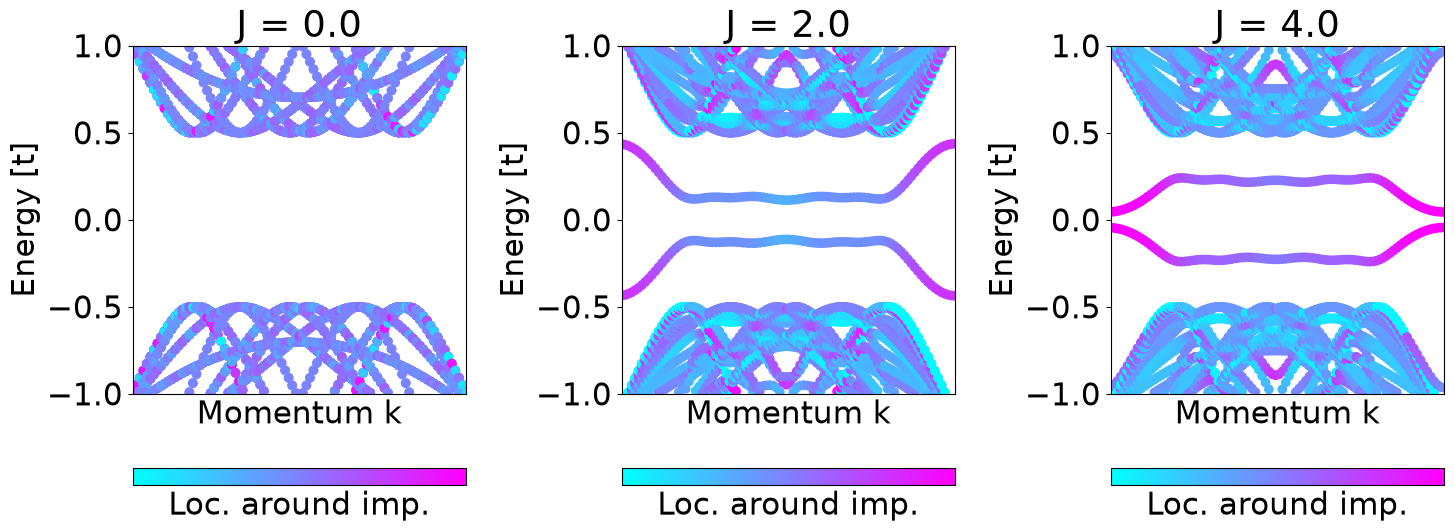

In [7]:
from pyqula import geometry, potentials
g = geometry.triangular_lattice() # take a triangular lattice
N = 7
g = g.get_supercell(N) # make a supercell
h = g.get_hamiltonian() # generate Hamiltonian
h.turn_dense()
delta = 5e-1 # pairing
h.add_swave(delta) # add swave superconductivity 

fig = plt.figure(figsize=(15,6))

pot = potentials.impurity(g.r[0],v=1.0) # potential for an impurity
nns = g.get_connections()[0] # get NN of site 0
NNpot = sum([potentials.impurity(g.r[i],v=1.0) for i in nns]) # potential for an impurity
# redefine the operator so that electron and hole components contribute equally
NNpot = h.get_operator(NNpot)*h.get_operator("electron") - h.get_operator(NNpot)*h.get_operator("hole")

def plot_bands(h):
    (ks,es,cs) = h.get_bands(operator=NNpot,nk=100)
    ewin = 1. # energy window to plot
    es,ks,cs = es[np.abs(es)<ewin],ks[np.abs(es)<ewin],cs[np.abs(es)<ewin]
    plt.scatter(ks,es,c=cs,cmap="cool")
    plt.ylabel("Energy [t]") ; plt.xlabel("Momentum k") 
    plt.colorbar(ticks=[],label="Loc. around imp.",orientation="horizontal")
    plt.ylim([-ewin,ewin]) ; plt.xticks([]) ; plt.xlim([min(ks),max(ks)])
    
Js = [0.,2.,4.] # exchange impurity potentials
nv = len(Js)
iv = 0
for J in Js:
    hi = h.copy() # make a copy
    hi.add_exchange(lambda r: [0.,0.,J*pot(r)]) # add exchange impurity potential
    plt.subplot(1,nv,iv+1) ; iv += 1 ; plt.title("J = "+str(J))
    plot_bands(hi) # make the plot

plt.tight_layout()

### Quiz
- Which one of the bands is the impurity band?
- Make the supercell bigger. What do you observe and why?
- Make the exchange coupling even bigger, what do you observe, and why?

## Single magnetic impurity in a superconductor (***Challenge***)
Now we will see how a magnetic impurity in a superconductor creates a bound state

This is the same Yu–Shiba–Rusinov physics mapped out continuously as a function of $J$: the in-gap bound state disperses from the gap edge at $J=0$ toward $E=0$ and beyond. For very strong $J$ the impurity site is effectively decoupled from the rest of the chain (the large exchange field pins the local spin and removes that site's spectral weight from the low-energy physics), so the in-gap feature merges back into the continuum.

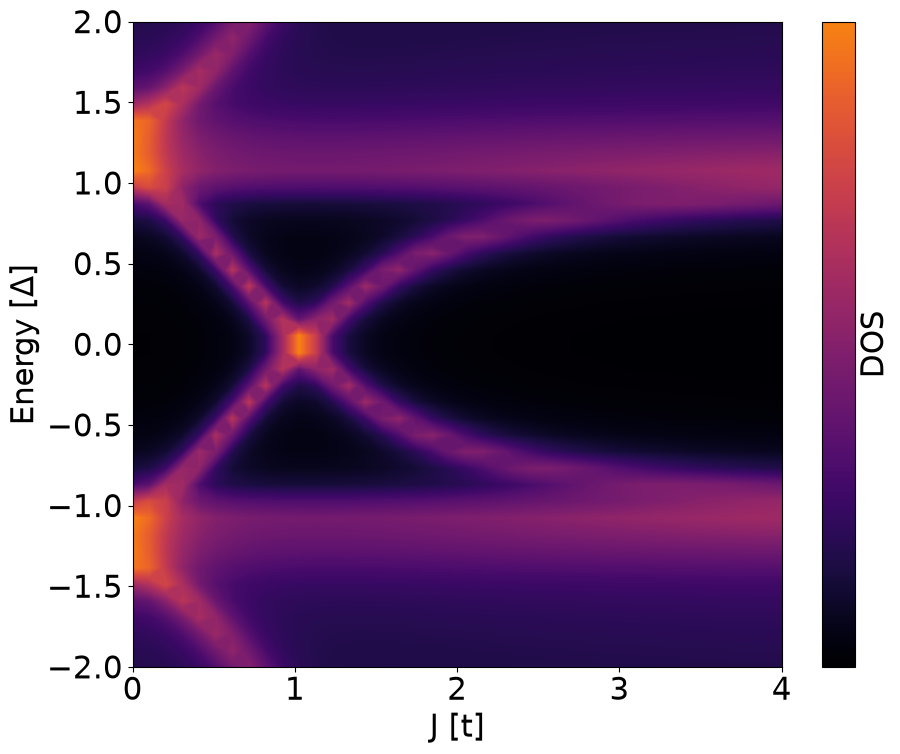

In [8]:
from pyqula import geometry
from pyqula import embedding
import numpy as np

fig = plt.figure(figsize=(10,8))

g = geometry.chain() # create geometry
g = g.get_supercell(3) # three sites per unit cell
J_arr,e_arr,d_arr = [],[],[] # empty list
Js = np.linspace(0.,4.0,40) # exchanges to consider
delta= 0.2 # superconducting order
energies = np.linspace(-2*delta,2*delta,40) # energies

# loop over the strength of the magnetic impurity
for J in Js: # loop over exchange
    h = g.get_hamiltonian() # get the Hamiltonian,spinful
    h.add_onsite(1.8) # shift chemical potential
    h.add_swave(delta) # add s-wave superconductivity
    hv = h.copy() # copy Hamiltonian to create a defective one
    # add magnetic site
    hv.add_exchange(lambda r: [0.,0.,(np.sum((r - g.r[0])**2)<1e-2)*J])
    eb = embedding.Embedding(h,m=hv) # create an embedding object
    d = [eb.dos(nsuper=2,delta=delta/10,energy=ei) for ei in energies] # compute DOS
    d = np.array(d) #; d = d/np.max(d) # normalize
    J_arr.append(J + energies*0.) # store exchange
    d_arr.append(d) # store DOS
    e_arr.append(energies) # store energies
    
plt.contourf(J_arr,np.array(e_arr)/delta,d_arr,cmap="inferno",vmax=5*np.mean(d_arr),levels=200)
plt.xlim([min(Js),max(Js)]); plt.ylim([-2,2])
plt.xlabel("J [t]") ; plt.ylabel("Energy [$ \\Delta $]")
plt.colorbar(label="DOS",ticks=[])
plt.tight_layout()

### Quiz
- Which point corresponds to a system without an impurity?
- Why does a magnetic impurity create an in-gap state?
- Change the chemical potential of the chain, does the previous behavior change? Explain why.
- The in-gap mode disappears for a very strong impurity. Explain why.

## Extended and localized states in quasicrystals (***Challenge***)
We will now see how extended and localized states can appear in a quasicrystal

This is the Aubry–André model: an incommensurate potential $V\cos(2\pi\alpha x)$ with irrational $\alpha$. Unlike random disorder, it produces a sharp localization transition at a critical strength $V_c=2t$ — states are extended ($1/\lambda\to0$) below $V_c$ and localized above it, and by self-duality of the model essentially *all* states localize simultaneously at the same $V_c$, rather than localizing one by one as disorder increases.

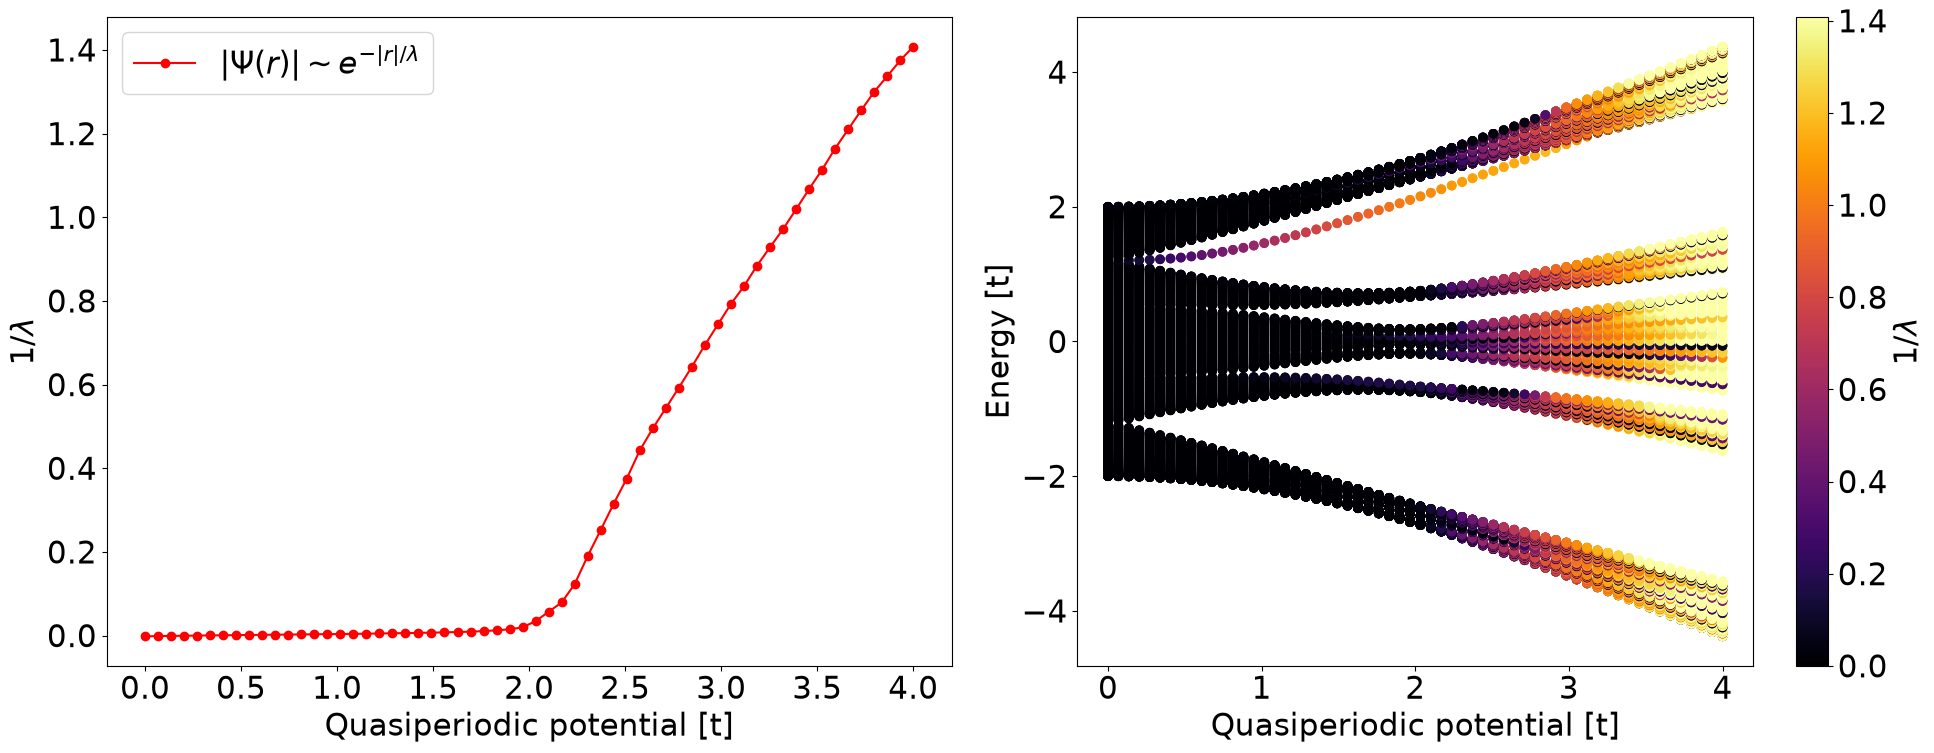

In [9]:

from pyqula import geometry
import numpy as np

g = geometry.chain(400) # chain
g.dimensionality = 0
vs = np.linspace(0.0,4.0,60) # potentials


lm = [] # empty array
larray = [] # empty array
earray = [] # empty array
varray = [] # empty array
for v in vs: # loop over strengths of the potential
    h = g.get_hamiltonian(has_spin=False) # get the Hamiltonian
    fun = lambda r: v*np.cos(np.sqrt(2)*np.pi*r[0]) # function with the quasiperiodic potential
    h.add_onsite(fun) # add onsite energies
    (es,ls) = h.get_tails() # return the localization length
    lm.append(np.mean(ls)) # store
    larray = np.concatenate([larray,ls]) # store localization lengths
    earray = np.concatenate([earray,es]) # store energies
    varray = np.concatenate([varray,es*0. + v]) # store potentials

# now plot the average localization length as a function of the potential
plt.subplot(1,2,1)
plt.plot(vs,lm,marker="o",c="red",label="$|\\Psi(r)|\\sim e^{-|r|/\\lambda}$")
plt.legend() 
plt.xlabel("Quasiperiodic potential [t]")
plt.ylabel("$1/\\lambda$")

# now plot the localization length for each state
plt.subplot(1,2,2)
plt.scatter(varray,earray,marker="o",c=larray,cmap="inferno",vmin=0,vmax=np.max(lm))
plt.ylabel("Energy [t]")
plt.xlabel("Quasiperiodic potential [t]")
plt.colorbar(label="1/$\\lambda$")

plt.tight_layout()


### Quiz
- How do you know which states are localized and which ones are extended from the localization length $\lambda$?
- In the plot above, which states are localized?
- In the plots above, which states are delocalized?
- Can you observe a critical point where the states go from delocalized to localized?
- Change the wavelength of the quasiperiodic potential, how does the previous picture change? 

## Localization due to random disorder (***Core***)
Here we will see how states get localized in the presence of random disorder, leading to an Anderson insulator

In one dimension, Anderson localization is more severe than the quasiperiodic case above: *any* nonzero random disorder localizes every state, however weak — there is no true extended phase in 1D. The localization length simply decreases smoothly with disorder strength (roughly $\lambda\propto 1/W^2$ for weak disorder), rather than showing the sharp transition seen for the quasiperiodic potential.

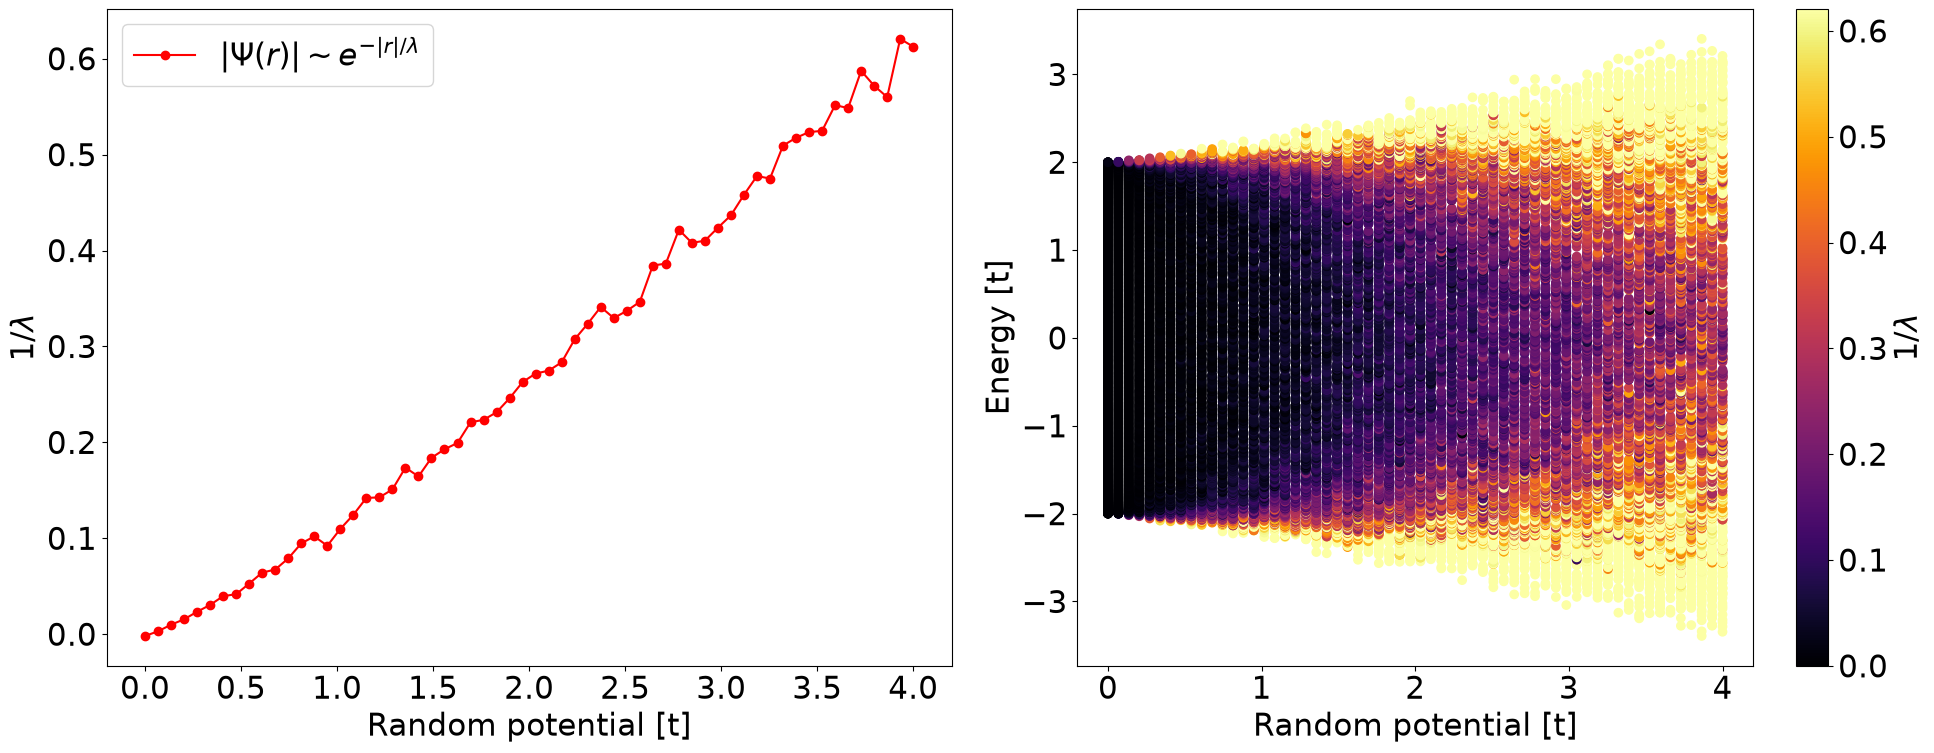

In [10]:

from pyqula import geometry
import numpy as np

g = geometry.chain(400) # chain
g.dimensionality = 0
vs = np.linspace(0.0,4.0,60) # potentials


lm = [] # empty array
larray = [] # empty array
earray = [] # empty array
varray = [] # empty array
for v in vs: # loop over strengths of the potential
    h = g.get_hamiltonian(has_spin=False) # get the Hamiltonian
    fun = lambda r: v*(np.random.random()-0.5) # function with the random potential
    h.add_onsite(fun) # add onsite energies
    (es,ls) = h.get_tails() # return the localization length
    lm.append(np.mean(ls)) # store
    larray = np.concatenate([larray,ls]) # store localization lengths
    earray = np.concatenate([earray,es]) # store energies
    varray = np.concatenate([varray,es*0. + v]) # store potentials

# now plot the average localization length as a function of the potential
plt.subplot(1,2,1)
plt.plot(vs,lm,marker="o",c="red",label="$|\\Psi(r)|\\sim e^{-|r|/\\lambda}$")
plt.legend() 
plt.xlabel("Random potential [t]")
plt.ylabel("$1/\\lambda$")

# now plot the localization length for each state
plt.subplot(1,2,2)
plt.scatter(varray,earray,marker="o",c=larray,cmap="inferno",vmin=0,vmax=np.max(lm))
plt.ylabel("Energy [t]")
plt.xlabel("Random potential [t]")
plt.colorbar(label="1/$\\lambda$")

plt.tight_layout()


### Quiz
- How do you know which states are localized and which ones are extended from the localization length $\lambda$?
- Which states are the most localized?
- From the plot in the left, what is the minimal disorder to localize the states?
- Which type of material is the system in the presence of disorder?

## Non-magnetic impurities in a topological superconductor (***Challenge***)

Because chiral p-wave pairing breaks time-reversal symmetry, it is not protected by Anderson's theorem the way the s-wave gap is: a non-magnetic impurity can still scatter Cooper pairs and pull a state into the gap. The band highlighted here (weighted by the impurity's local spectral weight) is this impurity-induced in-gap band, whose degree of localization around the impurity grows with the impurity strength $V$.

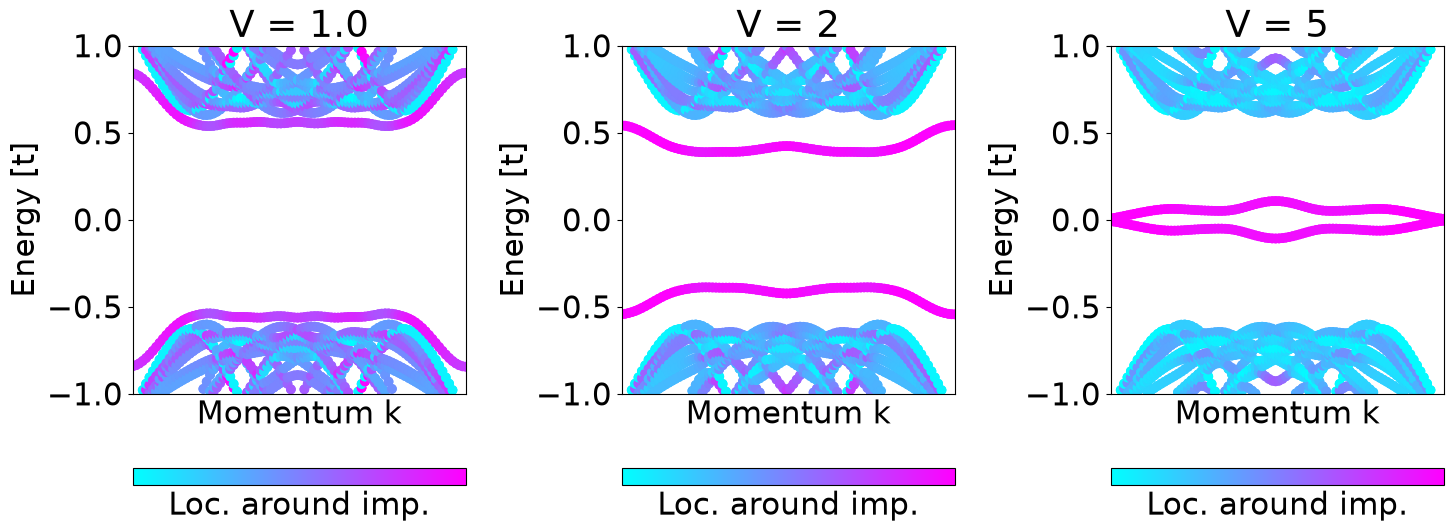

In [11]:
from pyqula import geometry, potentials
g = geometry.triangular_lattice() # take a triangular lattice
N = 7
g = g.get_supercell(N) # make a supercell
h = g.get_hamiltonian() # generate Hamiltonian
delta = 2e-1 # pairing
h.add_pairing(mode="chiral_pwave",delta=delta) # add pwave superconductivity
#h.add_pairing(mode="swave",delta=2*delta) # add swave superconductivity 
fig = plt.figure(figsize=(15,6))



pot = potentials.impurity(g.r[0],v=1.0) # potential for an impurity
nns = g.get_connections()[0] # get NN of site 0
NNpot = sum([potentials.impurity(g.r[i],v=1.0) for i in nns]) # potential for an impurity

# redefine the operator so that electron and hole components contribute equally
NNpot = h.get_operator(NNpot)*h.get_operator("electron") - h.get_operator(NNpot)*h.get_operator("hole")

def plot_bands(h):
    (ks,es,cs) = h.get_bands(operator=NNpot,nk=100)
    ewin = 1. # energy window to plot
    es,ks,cs = es[np.abs(es)<ewin],ks[np.abs(es)<ewin],cs[np.abs(es)<ewin]
    plt.scatter(ks,es,c=cs,cmap="cool")
    plt.ylabel("Energy [t]") ; plt.xlabel("Momentum k") 
    plt.colorbar(ticks=[],label="Loc. around imp.",orientation="horizontal")
    plt.ylim([-ewin,ewin]) ; plt.xticks([]) ; plt.xlim([min(ks),max(ks)])
    
vs = [1.,2,5] # impurity potentials
nv = len(vs)
iv = 0
for v in vs:
    hi = h.copy() # make a copy
    hi.add_onsite(v*pot) # add impurity potential
    plt.subplot(1,nv,iv+1) ; iv += 1 ; plt.title("V = "+str(v))
    plot_bands(hi) # make the plot

plt.tight_layout()

### Quiz
- Which one of the bands is the impurity band?
- Make the supercell smaller. What do you see and why?
- Make the supercell bigger. What do you observe and why?
- Replace the pwave superconductivity by swave superconductivity. What do you observe and why?

## DOS of non-magnetic impurities in a topological superconductor (***Challenge***)
Here we will see how vacancies in a topological superconductor gives rise to an in-gap mode. We will take a big unit cell, and put a vacancy on it

A strong enough non-magnetic impurity locally mimics a boundary of the sample, and since the chiral p-wave superconductor is topological (finite Chern number), the bulk-boundary correspondence from session 3 applies even to this local "hole" in the lattice: an in-gap peak appears in the DOS, the real-space analogue of the edge states found in a ribbon.

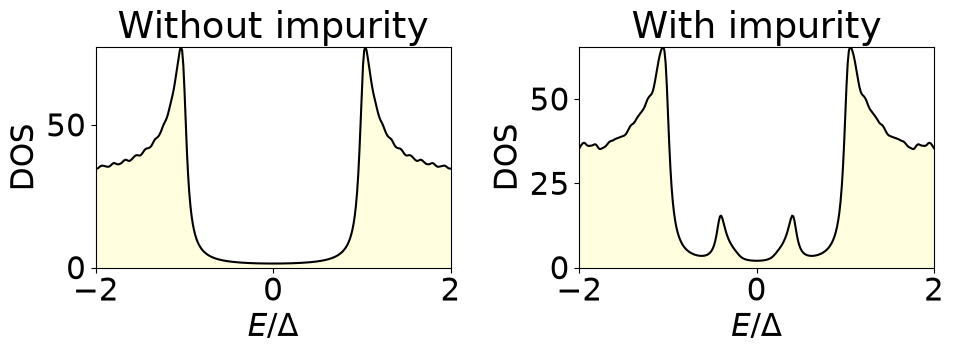

In [12]:
from pyqula import geometry, potentials
g = geometry.triangular_lattice() # take a triangular lattice
N = 10 # supercell where the impurity is put
h = g.get_hamiltonian() # generate Hamiltonian
h.add_onsite(-2.0) # shift the chemical potential
delta = 2e-1 # superconducting order parameter (very small to have nearly constant DOS in the energy window)
h.add_pairing(mode="chiral_pwave",delta=delta) # add topological superconductivity 
h = h.get_supercell(N) # make a supercell so that we have several sites per unit cell
h0 = h.copy() # make copy
h.add_onsite(potentials.impurity(h.geometry.r[0],v=4.0)) # add a strong non-magnetic impurity

gap = h0.get_gap()/2. # compute the gap
#gap = 1.0
energies = np.linspace(-2*gap,2*gap,301) # energy grid



def plot_dos(h):
    (e,d) = h.get_dos(energies=energies,delta=gap/20,nk=20) # compute DOS
    e = e/gap # redefine
    plt.plot(e,d,c="black") ; plt.xlabel("$E/\\Delta$") ; plt.ylabel("DOS") # plot
    plt.fill_between(e, d, where=d>=d, interpolate=True, color='lightyellow') # add a background
    dmax = np.max(d)
    plt.xlim([min(e),max(e)]) ; plt.ylim([0,dmax])

    # first the pristine
fig = plt.figure(figsize=(10,4))
plt.subplot(1,2,1) ; plt.title("Without impurity")
plot_dos(h0)
# now compute the DOS for the system with the impurity included in the Hamiltonian
plt.subplot(1,2,2) ; plt.title("With impurity")
plot_dos(h)


plt.tight_layout()

### Quiz
- Why do we have an ingap state with a non-magnetic impurity for a chiral pwave superconductor?
- Replace the non-magnetic impurity by a magnetic impurity, do we still have the in-gap state? Why?

## Single vacancy in a topological superconductor (***Challenge***)
Here we will see how a vacancy in a topological superconductor gives rise to an in-gap mode

Pushing the impurity potential to $V\to\infty$ turns it into a true vacancy, and the same topological argument holds: the in-gap resonance seen in the total DOS is the vacancy acting as a local boundary of the topological superconductor. Replacing the chiral p-wave order by trivial s-wave pairing removes this state entirely, since there is then no topology to protect a bound state at the defect.

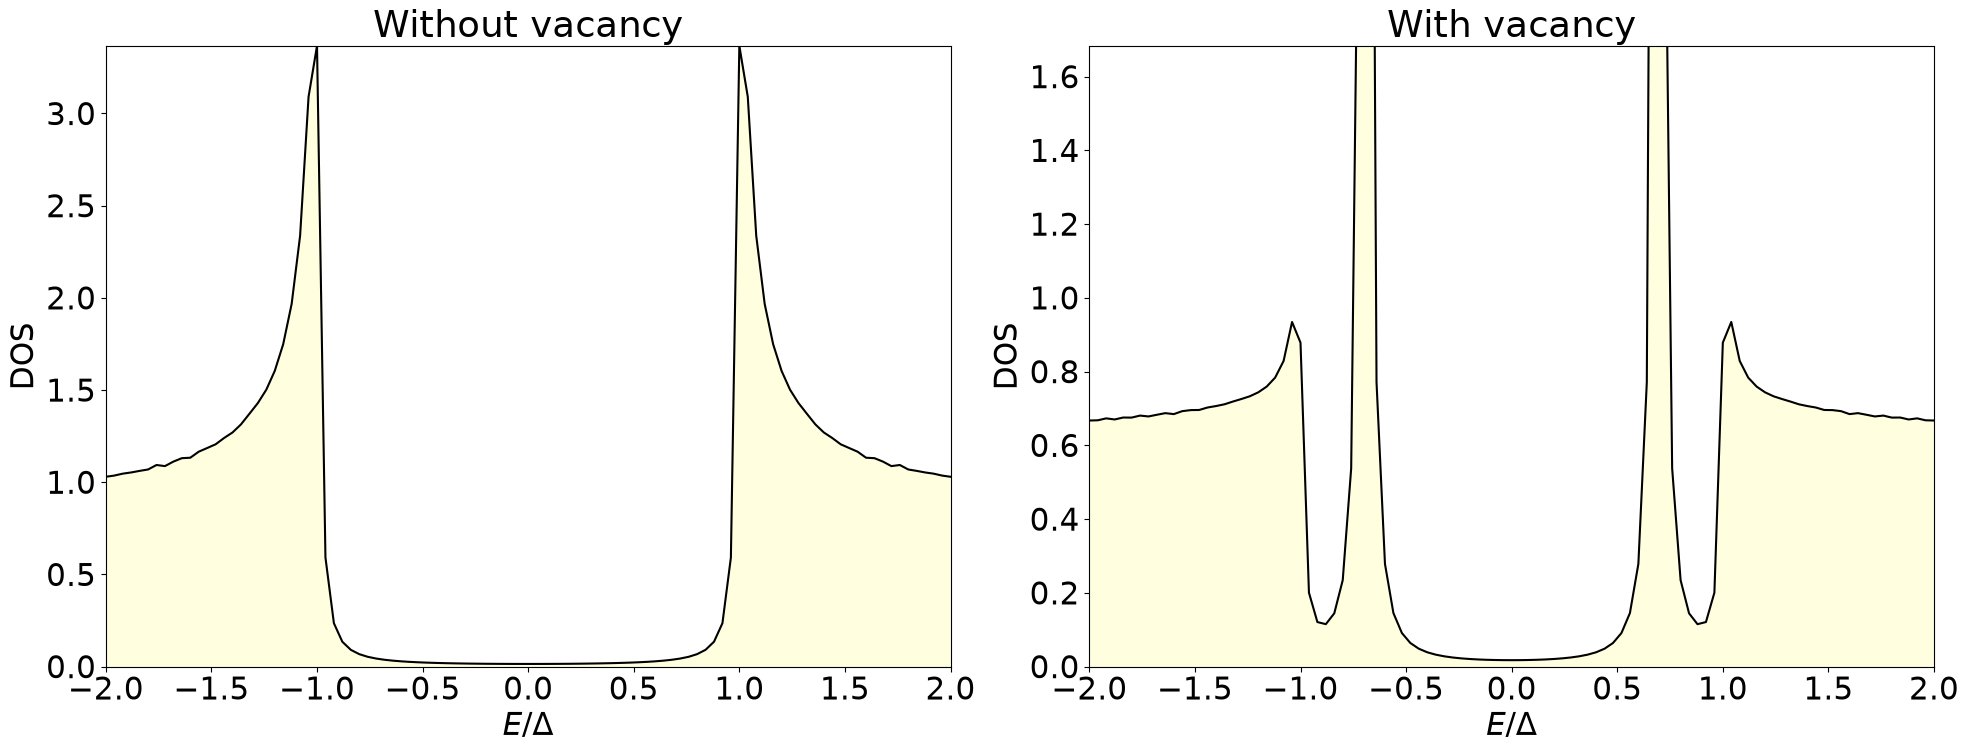

In [13]:
from pyqula import geometry, potentials, embedding
g = geometry.triangular_lattice() # take a triangular lattice
g = g.get_supercell((2,2)) # make a supercell so that we have several sites per unit cell
h = g.get_hamiltonian() # generate Hamiltonian
h.add_onsite(-4.0) # shift the chemical potential
delta = 1e-1 # superconducting order parameter
h.add_pairing(mode="chiral_pwave",delta=delta) # add topological superconductivity 
#h.add_pairing(mode="swave",delta=delta) # add trivial superconductivity 

fig = plt.figure(figsize=(20,8))

gap = h.get_gap()/2. # compute the gap

hv = h.copy() # make a copy
hv.add_onsite(potentials.impurity(g.r[0],v=100.0)) # unit cell with a strong non-magnetic impurity

# first the pristine
plt.subplot(1,2,1) ; plt.title("Without vacancy")
eb = embedding.Embedding(h,m=h) 
energies = np.linspace(-2*gap,2*gap,101) # energy grid
(e,d) = eb.multidos(es=energies,delta=gap/60,nk=400) # compute DOS
e = e/gap # redefine
plt.plot(e,d,c="black") ; plt.xlabel("$E/\\Delta$") ; plt.ylabel("DOS") # plot
plt.fill_between(e, d, where=d>=d, interpolate=True, color='lightyellow') # add a background
dmax = np.max(d)
plt.xlim([min(e),max(e)]) ; plt.ylim([0,dmax])

# create an embedding object (infinite pristine system with h, central impurity hv)
plt.subplot(1,2,2) ; plt.title("With vacancy")
eb = embedding.Embedding(h,m=hv) 
(e,d) = eb.multidos(es=energies,delta=gap/60,nk=400) # compute DOS
e = e/gap # redefine
plt.plot(e,d,c="black") ; plt.xlabel("$E/\\Delta$") ; plt.ylabel("DOS") # plot
plt.fill_between(e, d, where=d>=d, interpolate=True, color='lightyellow') # add a background
plt.xlim([min(e),max(e)]) ; plt.ylim([0,dmax/2])

plt.tight_layout()

### Quiz
- Why does an in-gap mode appear when you include a very strong impurity?
- Replace the topological gap by a trivial gap (add_pairing(mode="swave")). What happens with the impurity state?

## Vacancies in a topological insulator (***Challenge***)

The same reasoning applies to the Chern insulator (Haldane) gap: since it is topologically nontrivial, an impurity strong enough to locally act as a boundary pulls an in-gap band into the gap, growing more localized around the impurity as its strength increases — the electronic analogue of the topological superconductor case above.

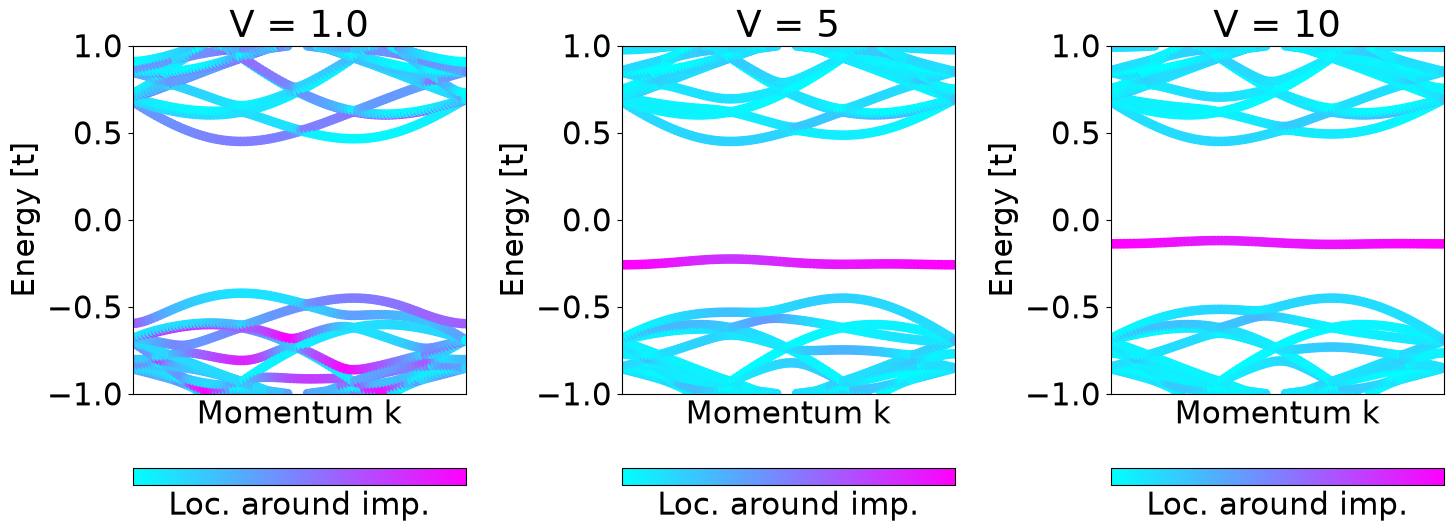

In [14]:
from pyqula import geometry, potentials
g = geometry.honeycomb_lattice() # take a honeycomb lattice
N = 7
g = g.get_supercell(N) # make a supercell
h = g.get_hamiltonian(has_spin=False) # generate Hamiltonian
h.add_haldane(0.1) # add a topological gap
#h.add_sublattice_imbalance(0.4) # trivial gap

fig = plt.figure(figsize=(15,6))

#gap = h.get_gap()/2. # gap of the system


hv = h.copy() # make a copy
pot = potentials.impurity(g.r[0],v=1.0) # potential for an impurity
nns = g.get_connections()[0] # get NN of site 0
NNpot = sum([potentials.impurity(g.r[i],v=1.0) for i in nns]) # potential for an impurity

def plot_bands(h):
    (ks,es,cs) = h.get_bands(operator=NNpot,nk=100)
    ewin = 1. # energy window to plot
    es,ks,cs = es[np.abs(es)<ewin],ks[np.abs(es)<ewin],cs[np.abs(es)<ewin]
    plt.scatter(ks,es,c=cs,cmap="cool")
    plt.ylabel("Energy [t]") ; plt.xlabel("Momentum k") 
    plt.colorbar(ticks=[],label="Loc. around imp.",orientation="horizontal")
    plt.ylim([-ewin,ewin]) ; plt.xticks([]) ; plt.xlim([min(ks),max(ks)])
    
vs = [1.,5,10] # impurity potentials
nv = len(vs)
iv = 0
for v in vs:
    hi = h.copy() # make a copy
    hi.add_onsite(v*pot) # add impurity potential
    plt.subplot(1,nv,iv+1) ; iv += 1 ; plt.title("V = "+str(v))
    plot_bands(hi) # make the plot

plt.tight_layout()

### Quiz
- Which one of the bands is the impurity band?
- Make the supercell smaller. What do you see and why?
- Make the supercell bigger. What do you observe and why?

## Single vacancy in a topological insulator (***Challenge***)
Here we will see how a vacancy in a topological insulator creates an in-gap state

As with the superconducting case, a true vacancy ($V\to\infty$) in the topological (Haldane) gap produces an in-gap resonance in the DOS — a local realization of the edge state expected at any boundary of a Chern insulator. Replacing the topological gap by a trivial sublattice-imbalance gap removes the in-gap state, since there is no longer any topological invariant protecting it.

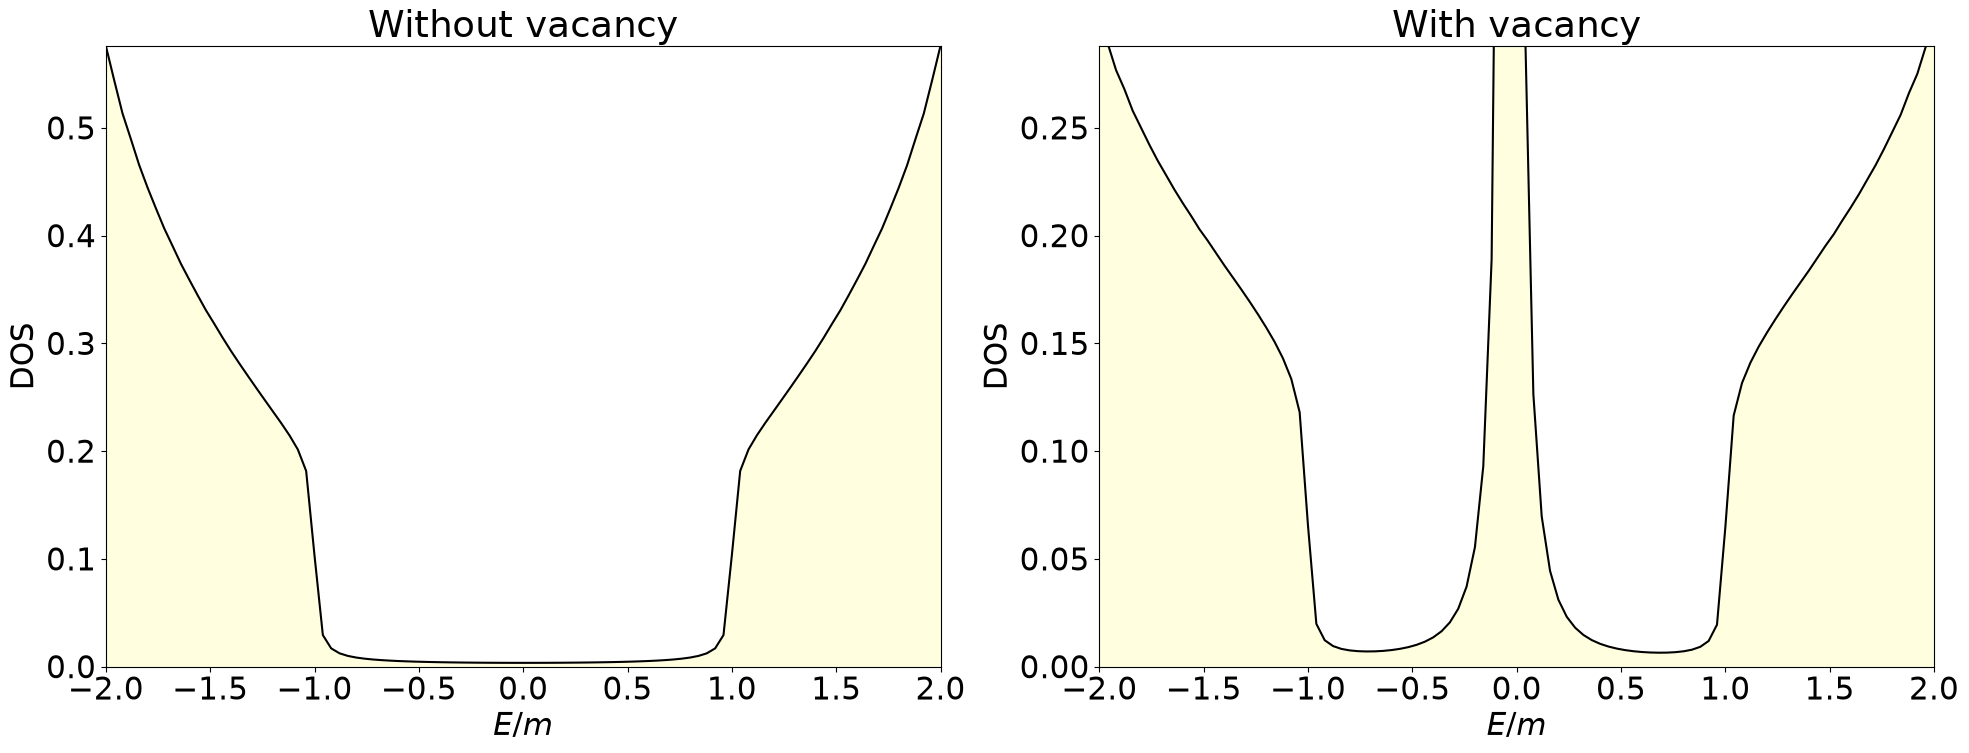

In [15]:
from pyqula import geometry, potentials, embedding
g = geometry.honeycomb_lattice() # take a honeycomb lattice
h = g.get_hamiltonian(has_spin=False) # generate Hamiltonian
h.add_haldane(0.1) # add a topological gap
#h.add_sublattice_imbalance(0.4) # trivial gap

fig = plt.figure(figsize=(20,8))

gap = h.get_gap()/2. # gap of the system


hv = h.copy() # make a copy
hv.add_onsite(potentials.impurity(h.geometry.r[0],v=100.0)) # unit cell with a strong non-magnetic impurity

# first the pristine
plt.subplot(1,2,1) ; plt.title("Without vacancy")
eb = embedding.Embedding(h,m=h) 
energies = np.linspace(-2*gap,2*gap,101) # energy grid
(e,d) = eb.multidos(es=energies,delta=gap/60,nk=400) # compute DOS
e = e/gap # redefine
plt.plot(e,d,c="black") ; plt.xlabel("$E/m$") ; plt.ylabel("DOS") # plot
plt.fill_between(e, d, where=d>=d, interpolate=True, color='lightyellow') # add a background
dmax = np.max(d)
plt.xlim([min(e),max(e)]) ; plt.ylim([0,dmax])

# create an embedding object (infinite pristine system with h, central impurity hv)
plt.subplot(1,2,2) ; plt.title("With vacancy")
eb = embedding.Embedding(h,m=hv) 
(e,d) = eb.multidos(es=energies,delta=gap/60,nk=400) # compute DOS
e = e/gap # redefine
plt.plot(e,d,c="black") ; plt.xlabel("$E/m$") ; plt.ylabel("DOS") # plot
plt.fill_between(e, d, where=d>=d, interpolate=True, color='lightyellow') # add a background
plt.xlim([min(e),max(e)]) ; plt.ylim([0,dmax/2.])

plt.tight_layout()

### Quiz
- Why does an in-gap mode appear when you include a very strong impurity?
- Replace the topological gap by a trivial gap (add_sublattice_imbalance). What happens with the impurity state?

## The charge-charge response function (***Challenge***)
Here we will show the relationship between the electronic structure and the response function

The charge susceptibility $\chi(\mathbf q,\omega)=-i\int dt\,e^{i\omega t}\langle[n_{\mathbf q}(t),n_{-\mathbf q}(0)]\rangle$ traces out the particle-hole continuum of the band structure: $\mathrm{Im}\,\chi(q,\omega)$ is large wherever an electron can be scattered from an occupied to an empty state at momentum transfer $q$ and energy transfer $\omega$. Enhanced weight at $q=2k_F$ signals Fermi-surface nesting — the same momentum that would drive a charge-density-wave instability — and changing $\mu$ shifts $k_F$ and therefore where this weight sits.

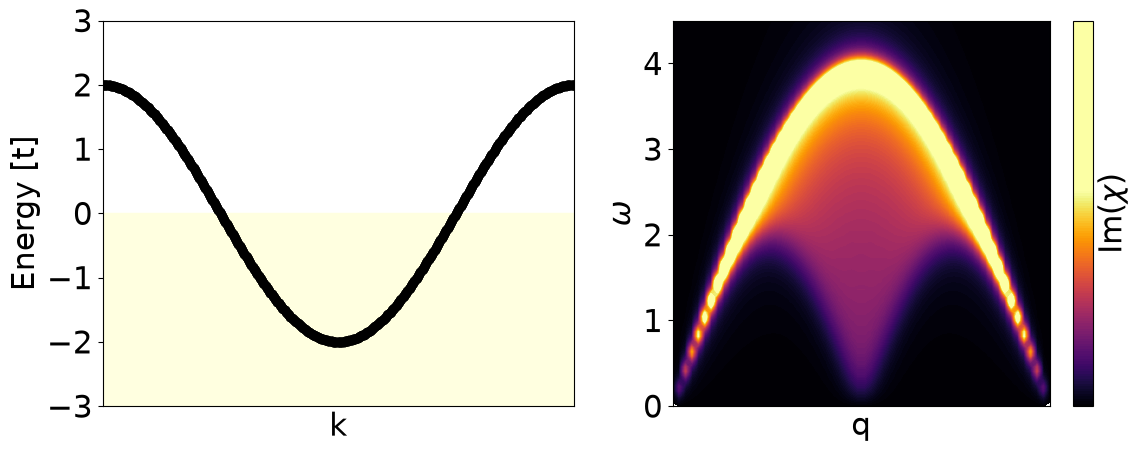

In [16]:
from pyqula import geometry
import numpy as np

g = geometry.chain()
h = g.get_hamiltonian() # generate Hamiltonian
mu = 0. # chemical potential

h.add_onsite(mu) # shift the chemical potential

energies = np.linspace(0.0,4.5,100) # energies
qs = np.linspace(0.,1.,60) # qvectors
q_arr,e_arr,c_arr = [],[],[]
for q in qs:
    e,c = h.get_chi(energies=energies,q=[q,0.,0.],nk=200)
    c_arr.append(c) # store response
    q_arr.append(q+energies*0.) # store q
    e_arr.append(energies) # store energies

# plot the band structure

fig = plt.figure(figsize=(12,5))
(k,e) = h.get_bands() # compute band structure
plt.subplot(1,2,1)
k = k/np.max(k)
plt.fill_between([0,1],-10,0,color="lightyellow")
plt.scatter(k,e,c="black") ; plt.xlim([0,1]) ; plt.ylim([-3,3])
plt.ylabel("Energy [t]") ; plt.xlabel("k") ; plt.xticks([])
# plot the response
plt.subplot(1,2,2)
c_arr = np.array(c_arr) # to array
plt.contourf(q_arr,e_arr,c_arr.imag,cmap="inferno",levels=200,vmin=0,vmax=4*np.mean(c_arr.imag))
plt.ylabel("$\\omega$") ; plt.xlabel("q") ; plt.xticks([]) ; plt.colorbar(label="Im($\\chi$)",ticks=[])
plt.tight_layout()

### Quiz
- The plot on the right shows the imaginary part of the charge response function. What does it mean?
- Can you predict the instabilities from the right plot. If so, how?
- Change the chemical potential $\mu$, what can you say about the instabilities of the system?

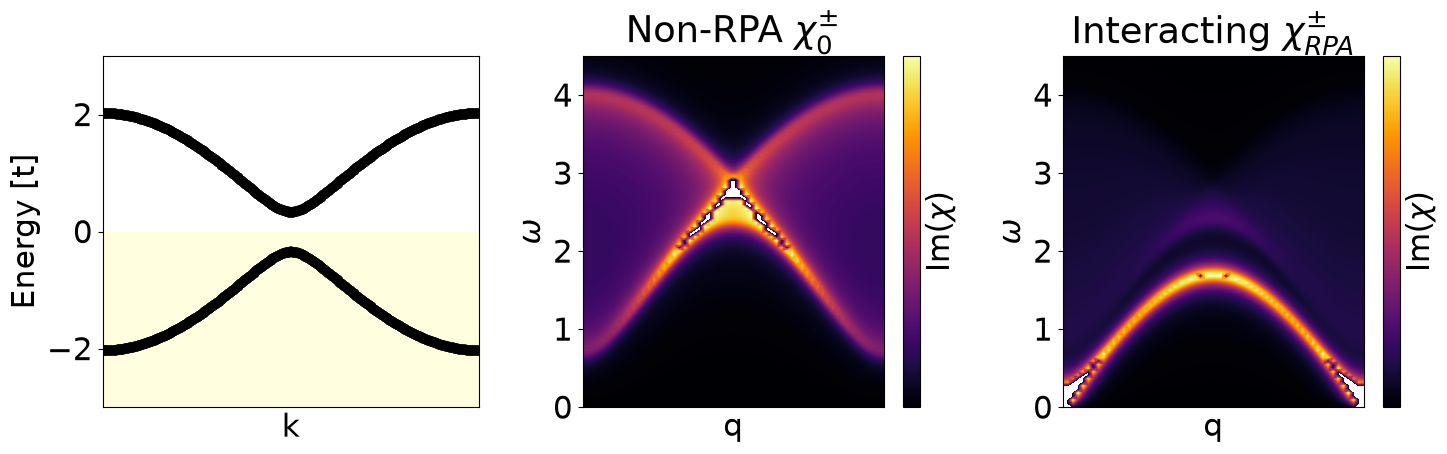

In [17]:
from pyqula import geometry
import numpy as np

g = geometry.bichain()
h = g.get_hamiltonian() # generate Hamiltonian
# h.add_antiferromagnetism(0.3) # external antiferromagnet field in the Hamiltonian


hmf = h.copy() ; hmf.add_antiferromagnetism(0.5)
U = 2.0 ; nk = 100
h = h.get_mean_field_hamiltonian(U=U,nk=nk,mf=hmf,filling=0.5)

energies = np.linspace(0.0,4.5,100) # energies
qs = np.linspace(0.,1.,60) # qvectors

def get_spin_response(h,**kwargs):
    c_arr = []
    for q in qs:
        e,c = h.get_spinchi_ladder(energies=energies,q=[q,0.,0.],nk=nk,imode="mesh",**kwargs)
        c = [np.trace(ci) for ci in c] # trace
        c_arr.append(c) # store response
    c_arr = np.array(c_arr).T
    return c_arr # return response

# plot the band structure
fig = plt.figure(figsize=(15,5))
(k,e) = h.get_bands() # compute band structure
plt.subplot(1,3,1)
k = k/np.max(k)
plt.fill_between([0,1],-10,0,color="lightyellow")
plt.scatter(k,e,c="black") ; plt.xlim([0,1]) ; plt.ylim([-3,3])
plt.ylabel("Energy [t]") ; plt.xlabel("k") ; plt.xticks([])
# plot the response
def plot_response(**kwargs):
    c_arr = get_spin_response(h,**kwargs)
    c_arr = np.array(c_arr) # to array
    zcut = np.percentile(c_arr.imag,99,axis=None)
    c_arr[c_arr.imag>zcut] = zcut
    plt.contourf(qs,energies,c_arr.imag,cmap="inferno",levels=400,vmin=0.,vmax=zcut)
    plt.ylabel("$\\omega$") ; plt.xlabel("q") ; plt.xticks([]) ; plt.colorbar(label="Im($\\chi$)",ticks=[])

plt.subplot(1,3,2) ; plt.title("Non-RPA $\\chi^{\\pm}_0$")
plot_response(RPA=False)

plt.subplot(1,3,3) ; plt.title("Interacting $\\chi^{\\pm}_{RPA}$")
plot_response(RPA=True)
plt.tight_layout()

### Quiz
- Increase the interaction U, what happens and why?
- Add an external antiferromagnetic field to the Hamiltonian, what happens and why?